# Intermittent Demand Forecasting
## Syntetos–Boylan Approximation (SBA)

SBA is a bias-adjusted version of Croston's method for intermittent demand. Croston separately smooths non-zero demand sizes and the intervals between them. SBA then applies a correction factor:

$$\hat{y}_{t+h}^{SBA} = \left(1-\frac{\alpha}{2}\right)\frac{\hat{z}_t}{\hat{p}_t}$$

where `alpha` is the smoothing parameter used for both size and interval estimates in this implementation.

The correction reduces Croston's tendency to over-forecast on average under the assumptions behind the method. It does not guarantee better accuracy on every individual series.

This notebook implements SBA independently, then compares it with Croston and simple baselines.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
np.random.seed(42)

## 1. Generate synthetic intermittent demand

We use a reproducible monthly demand series with many zero periods and occasional non-zero demand.

In [2]:
n_periods = 120
occurs = np.random.rand(n_periods) < 0.25
sizes = np.random.randint(5, 31, size=n_periods)
demand = np.where(occurs, sizes, 0)
dates = pd.date_range("2016-01-01", periods=n_periods, freq="MS")
series = pd.Series(demand, index=dates, name="Demand")

print(series.head(24))
print(f"Zero periods: {(series == 0).sum()} / {len(series)}")

2016-01-01     0
2016-02-01     0
2016-03-01     0
2016-04-01     0
2016-05-01     5
2016-06-01     5
2016-07-01    29
2016-08-01     0
2016-09-01     0
2016-10-01     0
2016-11-01    13
2016-12-01     0
2017-01-01     0
2017-02-01    10
2017-03-01    12
2017-04-01    13
2017-05-01     0
2017-06-01     0
2017-07-01     0
2017-08-01     0
2017-09-01     0
2017-10-01    28
2017-11-01     0
2017-12-01     0
Freq: MS, Name: Demand, dtype: int64
Zero periods: 85 / 120


## 2. Visualize the demand pattern

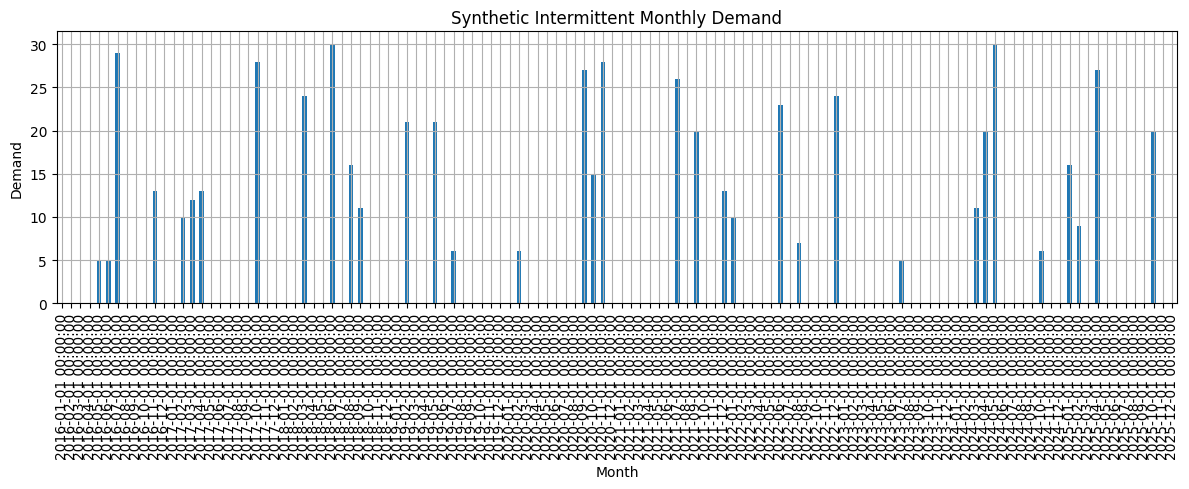

In [3]:
series.plot(kind="bar", title="Synthetic Intermittent Monthly Demand")
plt.xlabel("Month")
plt.ylabel("Demand")
plt.tight_layout()
plt.show()

## 3. Implement Croston estimates and SBA correction

The state updates are the same as Croston's method. SBA multiplies the Croston rate by `(1 - alpha / 2)`. This implementation uses the same alpha for demand-size and interval smoothing.

In [4]:
def sba_forecast(y, alpha=0.1):
    """SBA forecast with explicit first-nonzero initialization.

    Returns Croston and SBA rates, fitted series, and state history.
    """
    y = np.asarray(y, dtype=float)
    if y.ndim != 1:
        raise ValueError("y must be one-dimensional")
    if len(y) == 0:
        raise ValueError("y must not be empty")
    if np.any(y < 0):
        raise ValueError("Demand must be non-negative")
    if not 0 < alpha <= 1:
        raise ValueError("alpha must be in (0, 1]")

    nz = np.flatnonzero(y > 0)
    croston_fitted = np.zeros(len(y), dtype=float)
    sba_fitted = np.zeros(len(y), dtype=float)

    if len(nz) == 0:
        return {
            "croston_forecast": 0.0,
            "sba_forecast": 0.0,
            "croston_fitted": croston_fitted,
            "sba_fitted": sba_fitted,
            "history": pd.DataFrame(columns=["period", "demand_size_est", "interval_est",
                                             "croston_rate", "sba_rate"])
        }

    first = nz[0]
    z_hat = y[first]
    p_hat = first + 1
    q = 0
    rows = []

    for t, value in enumerate(y):
        if t < first:
            rows.append((t, np.nan, np.nan, 0.0, 0.0))
            continue
        if t == first:
            croston_rate = z_hat / p_hat
            sba_rate = (1 - alpha / 2) * croston_rate
            croston_fitted[t] = croston_rate
            sba_fitted[t] = sba_rate
            rows.append((t, z_hat, p_hat, croston_rate, sba_rate))
            q = 0
            continue

        q += 1
        if value > 0:
            z_hat = z_hat + alpha * (value - z_hat)
            p_hat = p_hat + alpha * (q - p_hat)
            q = 0

        croston_rate = z_hat / p_hat
        sba_rate = (1 - alpha / 2) * croston_rate
        croston_fitted[t] = croston_rate
        sba_fitted[t] = sba_rate
        rows.append((t, z_hat, p_hat, croston_rate, sba_rate))

    history = pd.DataFrame(rows, columns=[
        "period", "demand_size_est", "interval_est", "croston_rate", "sba_rate"
    ])
    return {
        "croston_forecast": float(z_hat / p_hat),
        "sba_forecast": float((1 - alpha / 2) * z_hat / p_hat),
        "croston_fitted": croston_fitted,
        "sba_fitted": sba_fitted,
        "history": history
    }

## 4. Run SBA

The correction factor is determined by alpha. For example, if alpha is 0.1, the SBA correction factor is 0.95.

In [5]:
alpha = 0.1
result = sba_forecast(series.values, alpha=alpha)
correction = 1 - alpha / 2

print(f"Alpha: {alpha}")
print(f"SBA correction factor: {correction:.3f}")
print(f"Croston rate: {result['croston_forecast']:.3f}")
print(f"SBA forecast per month: {result['sba_forecast']:.3f}")
display(result["history"].tail(10))

Alpha: 0.1
SBA correction factor: 0.950
Croston rate: 4.745
SBA forecast per month: 4.507


,period,demand_size_est,interval_est,croston_rate,sba_rate
110,110,15.259253,3.405868,4.480282,4.256268
111,111,16.433327,3.265282,5.032744,4.781107
112,112,16.433327,3.265282,5.032744,4.781107
113,113,16.433327,3.265282,5.032744,4.781107
114,114,16.433327,3.265282,5.032744,4.781107
115,115,16.433327,3.265282,5.032744,4.781107
116,116,16.433327,3.265282,5.032744,4.781107
117,117,16.789995,3.538753,4.744607,4.507377
118,118,16.789995,3.538753,4.744607,4.507377
119,119,16.789995,3.538753,4.744607,4.507377


## 5. Plot actual demand and SBA fitted rate

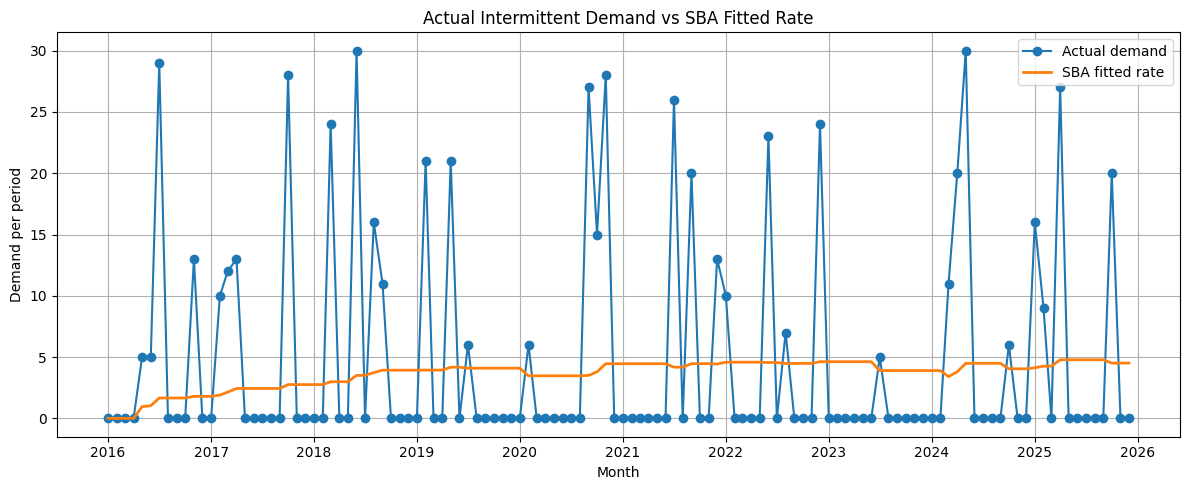

In [6]:
sba_fitted = pd.Series(result["sba_fitted"], index=series.index)
plt.figure()
plt.plot(series.index, series.values, marker="o", label="Actual demand")
plt.plot(series.index, sba_fitted, linewidth=2, label="SBA fitted rate")
plt.title("Actual Intermittent Demand vs SBA Fitted Rate")
plt.xlabel("Month")
plt.ylabel("Demand per period")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Forecast future periods

,SBA forecast
2026-01-01,4.507377
2026-02-01,4.507377
2026-03-01,4.507377
2026-04-01,4.507377
2026-05-01,4.507377
2026-06-01,4.507377
2026-07-01,4.507377
2026-08-01,4.507377
2026-09-01,4.507377
2026-10-01,4.507377


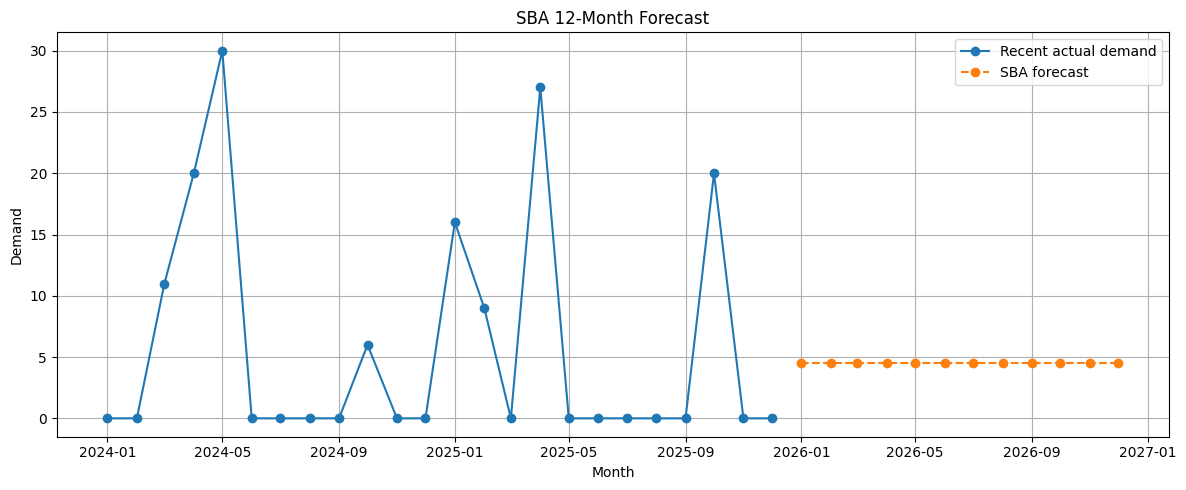

In [7]:
horizon = 12
future_dates = pd.date_range(series.index[-1] + pd.offsets.MonthBegin(1),
                             periods=horizon, freq="MS")
future = pd.Series(result["sba_forecast"], index=future_dates, name="SBA forecast")
display(future.to_frame())

plt.figure()
plt.plot(series.index[-24:], series.values[-24:], marker="o", label="Recent actual demand")
plt.plot(future.index, future.values, marker="o", linestyle="--", label="SBA forecast")
plt.title("SBA 12-Month Forecast")
plt.xlabel("Month")
plt.ylabel("Demand")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Compare Croston and SBA

SBA applies a downward correction to the Croston rate. The size of the adjustment depends on alpha.

In [8]:
comparison = pd.DataFrame({
    "Method": ["Croston", "SBA"],
    "Forecast per month": [result["croston_forecast"], result["sba_forecast"]]
})
display(comparison)

print("SBA / Croston ratio:", result["sba_forecast"] / result["croston_forecast"]
      if result["croston_forecast"] else np.nan)

,Method,Forecast per month
0,Croston,4.744607
1,SBA,4.507377


SBA / Croston ratio: 0.9500000000000001


## 8. Holdout evaluation

The model is estimated on the training segment only. Its rate forecast is held constant over the test horizon. MAPE is not recommended when actual values include zeros.

In [9]:
split = int(len(series) * 0.8)
train, test = series.iloc[:split], series.iloc[split:]
train_result = sba_forecast(train.values, alpha=alpha)

pred_sba = np.full(len(test), train_result["sba_forecast"])
pred_croston = np.full(len(test), train_result["croston_forecast"])

def score(actual, pred):
    actual = np.asarray(actual, dtype=float)
    pred = np.asarray(pred, dtype=float)
    return {
        "MAE": np.mean(np.abs(actual - pred)),
        "RMSE": np.sqrt(np.mean((actual - pred) ** 2)),
        "WMAPE": (np.sum(np.abs(actual - pred)) / np.sum(np.abs(actual))
                  if np.sum(np.abs(actual)) else np.nan)
    }

scores = pd.DataFrame([
    {"Method": "Croston", **score(test.values, pred_croston)},
    {"Method": "SBA", **score(test.values, pred_sba)}
]).set_index("Method")
display(scores)

,MAE,RMSE,WMAPE
Method,,,
Croston,7.158771,9.544923,1.236047
SBA,7.090416,9.583365,1.224244


## 9. Explore the effect of alpha

The correction factor changes with alpha. Alpha also changes the underlying smoothed size and interval estimates. Tune it on validation data rather than selecting it on the final test set.

In [10]:
rows = []
for a in [0.05, 0.1, 0.2, 0.3, 0.5]:
    r = sba_forecast(train.values, alpha=a)
    p = np.full(len(test), r["sba_forecast"])
    rows.append({
        "alpha": a,
        "correction_factor": 1 - a / 2,
        "Croston_rate": r["croston_forecast"],
        "SBA_rate": r["sba_forecast"],
        "holdout_MAE": np.mean(np.abs(test.values - p))
    })
display(pd.DataFrame(rows))

,alpha,correction_factor,Croston_rate,SBA_rate,holdout_MAE
0,0.05,0.975,3.496956,3.409532,6.928177
1,0.10,0.950,4.101312,3.896247,7.090416
2,0.20,0.900,3.700588,3.330529,6.901843
3,0.30,0.850,3.130364,2.660809,6.678603
4,0.50,0.750,2.246464,1.684848,6.353283


## 10. Advantages, limitations, and practical notes

**Advantages**
- Designed for intermittent demand.
- Retains Croston's separate smoothing of demand size and inter-demand interval.
- Applies a bias-reducing correction to the Croston rate.

**Limitations**
- The correction does not guarantee better accuracy for every series.
- Does not explicitly model seasonality, trend, or changing demand occurrence probability.
- Forecast remains constant across future periods.
- Initialization and alpha can influence results.

**Practical notes**
- Ensure zero values represent genuine no-demand periods, not missing data or stockouts.
- Use consistent time buckets and non-negative demand.
- Select alpha using validation data and evaluate with metrics suitable for zero-heavy data.
- Compare against Croston, TSB, and simple baselines.

## Key takeaway
SBA uses Croston's estimates of demand size and inter-demand interval, then multiplies the resulting demand rate by `(1 - alpha / 2)` to reduce Croston's bias under its theoretical assumptions.